# 01 — Cleaning and EDA

We ask which flights are eligible and what the original training data show.
The main cells are short; reusable source decoding and checks live in
[simple_workflow.py](../../scripts/simple_workflow.py). The label and treatment
rules remain visible. This notebook has **three figures**; other checks use tables.

All four notebooks explain and reproduce the completed project. July 2026 is
already exposed, and will not be used to choose features or models.
[Run guide](README.md) · [Objectives](../../OBJECTIVES.md)

In [1]:
from pathlib import Path
import sys
here = Path.cwd()
candidates = [here, *here.parents, here/'departure-delay-classification']
root = next(p for p in candidates if (p/'config/project.json').is_file())
sys.path.insert(0, str(root/'scripts'))
import simple_workflow as project

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style='whitegrid')

Matplotlib is building the font cache; this may take a moment.


## Load and inspect the raw flights

Read the same 17 archived BTS files, keeping ATL, ORD and DFW. The reader preserves
stable file/CSV-line IDs. `decode_flights` converts dates and finite numbers and
checks cancellation status and duplicate natural identities. It does not create labels.
The tables show source counts, sample rows, types and conversion failures.

In [3]:
flights, sources = project.read_development_flights()
flights, conversions = project.decode_flights(flights)
display(sources, flights.head())

2024_11: 75,647 scoped schedules


2024_12: 77,496 scoped schedules


2025_01: 70,648 scoped schedules


2025_02: 65,498 scoped schedules


2025_03: 78,143 scoped schedules


...

2026_01: 73,955 scoped schedules


2026_02: 70,581 scoped schedules


2026_03: 84,050 scoped schedules


,month,national_rows,scoped_rows
0,2024_11,575404,75647
1,2024_12,590581,77496
2,2025_01,539747,70648
3,2025_02,504884,65498
4,2025_03,600872,78143
5,2025_04,583950,77315
6,2025_05,605648,82443
7,2025_06,611575,85593
8,2025_07,631428,88013
9,2025_08,602378,84534


,flight_date,airline,flight_number,origin,destination,scheduled_departure_hhmm,departure_delay_minutes,departure_delay_15_source,cancelled,diverted,scheduled_duration_minutes,distance_miles,source_file,source_row_number,flight_id
0,2024-11-21,OO,3629,ATL,SHV,1320.0,-5.0,0.0,0.0,0.0,111.0,551.0,data/raw/flights/bts/2024_context/csv/2024_11.csv,73,2024_11:73
1,2024-11-21,OO,3645,ATL,SHV,2203.0,-8.0,0.0,0.0,0.0,113.0,551.0,data/raw/flights/bts/2024_context/csv/2024_11.csv,93,2024_11:93
2,2024-11-21,OO,3702,ATL,CRW,855.0,-4.0,0.0,0.0,0.0,87.0,363.0,data/raw/flights/bts/2024_context/csv/2024_11.csv,157,2024_11:157
3,2024-11-21,OO,3760,ATL,BQK,1045.0,-5.0,0.0,0.0,0.0,73.0,238.0,data/raw/flights/bts/2024_context/csv/2024_11.csv,216,2024_11:216
4,2024-11-21,OO,3810,ATL,CRW,2132.0,-6.0,0.0,0.0,0.0,84.0,363.0,data/raw/flights/bts/2024_context/csv/2024_11.csv,282,2024_11:282


In [4]:
flights.info()
display(conversions)
display(flights.isna().sum().rename('missing_count').to_frame())

<class 'pandas.DataFrame'>
RangeIndex: 1339044 entries, 0 to 1339043
Data columns (total 15 columns):
 #   Column                      Non-Null Count    Dtype         
---  ------                      --------------    -----         
 0   flight_date                 1339044 non-null  datetime64[ns]
 1   airline                     1339044 non-null  string        
 2   flight_number               1339044 non-null  string        
 3   origin                      1339044 non-null  string        
 4   destination                 1339044 non-null  string        
 5   scheduled_departure_hhmm    1339044 non-null  float64       
 6   departure_delay_minutes     1311118 non-null  float64       
 7   departure_delay_15_source   1311118 non-null  float64       
 8   cancelled                   1339044 non-null  float64       
 9   diverted                    1339044 non-null  float64       
 10  scheduled_duration_minutes  1339044 non-null  float64       
 11  distance_miles              1339044

,variable,unparseable
0,scheduled_departure_hhmm,0
1,scheduled_duration_minutes,0
2,distance_miles,0
3,departure_delay_minutes,0
4,departure_delay_15_source,0
5,cancelled,0
6,diverted,0


,missing_count
flight_date,0
airline,0
flight_number,0
origin,0
destination,0
scheduled_departure_hhmm,0
departure_delay_minutes,27926
departure_delay_15_source,27926
cancelled,0
diverted,0


## Create eligibility and the target

A flight must be noncancelled with a known departure delay. A later diversion does
not exclude a known departure. The target is 1 for departure delay ≥15 minutes;
ineligible rows remain unlabeled schedule/history context. These outcome columns
are excluded from predictors.

In [5]:
flights['label_eligible'] = flights['cancelled'].eq(0) & flights['departure_delay_minutes'].notna()
flights['delayed_departure'] = flights['departure_delay_minutes'].ge(15)
flights['delayed_departure'] = flights['delayed_departure'].where(flights['label_eligible']).astype('Int8')

## Define time and chronological roles

The timestamp step converts HHMM to minutes (1330 → 810), localizes with archived
airport time zones and subtracts two hours for the prediction cutoff. Invalid or
unresolved daylight-saving times stop execution. Actual departure time is audit/history
context only. The table separates schedules from eligible queries by original period.

In [6]:
flights = project.add_timestamps(flights)
flights = project.assign_periods(flights)
display(flights.groupby('split').agg(scheduled=('flight_id', 'size'), eligible=('query_eligible', 'sum')))

,scheduled,eligible
split,,
context,153143,0
test,228586,219748
train,712534,698670
validation,244781,239747


## Review distributions and outliers

Outcome EDA uses eligible January–September 2025 flights. Numerical summaries show
spread and skewness. The three outlier rules flag unusual values without deleting
them. Only nonpositive distance/duration becomes missing; valid extremes and the
label-defining delay remain unchanged. Missing predictors will be imputed during training.

In [7]:
train = flights.loc[flights['query_eligible'] & flights['split'].eq('train')].copy()
numeric = ['distance_miles', 'scheduled_duration_minutes', 'departure_delay_minutes']
display(train[numeric].describe().T, train[numeric].skew().rename('skewness'))
display(project.outlier_summary(train, numeric[:2]))

,count,mean,std,min,25%,50%,75%,max
distance_miles,698670.0,758.785707,498.860156,67.0,404.0,666.0,985.0,4502.0
scheduled_duration_minutes,698670.0,138.538174,63.715659,37.0,91.0,126.0,166.0,624.0
departure_delay_minutes,698670.0,17.131902,57.265011,-60.0,-5.0,-1.0,16.0,2364.0


distance_miles                1.510114
scheduled_duration_minutes    1.458038
departure_delay_minutes       8.108279
Name: skewness, dtype: float64

,variable,IQR_flags,three_SD_flags,above_p99
0,distance_miles,20787,2762,6431
1,scheduled_duration_minutes,27641,4093,6827


In [8]:
for column in numeric[:2]:
    invalid = flights[column].notna() & flights[column].le(0)
    flights[column+'_invalid'] = invalid.astype('int8')
    flights[column] = flights[column].mask(invalid)
project.check_cleaning(flights)

Cleaning matches the existing handoff: 1,339,044 rows; 24 columns.


In [9]:
train = flights.loc[train.index].copy()
plot_rows = train.sample(10000, random_state=42)
display(train['delayed_departure'].value_counts().rename('count').to_frame())

,count
delayed_departure,
0,518143
1,180527


The first figure retains the full sampled delay range: negative values are early
departures, while the long right tail contains real late departures. The boxplot
compares distance by outcome and shows substantial class overlap.

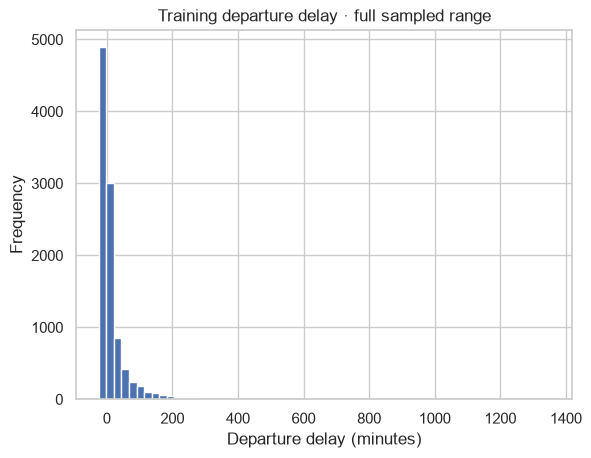

In [10]:
plot_rows['departure_delay_minutes'].plot.hist(bins=60, title='Training departure delay · full sampled range')
plt.xlabel('Departure delay (minutes)')
plt.show()

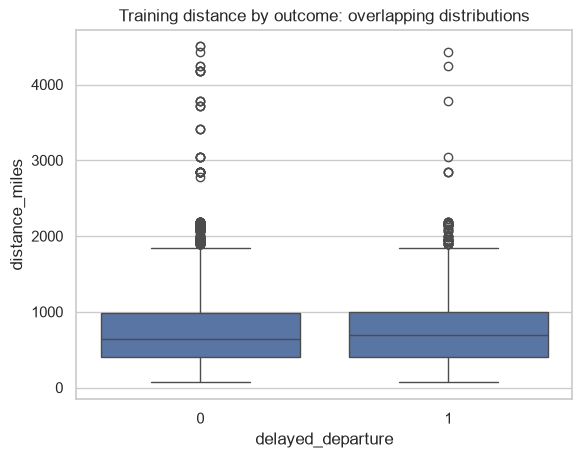

In [11]:
sns.boxplot(data=plot_rows, x='delayed_departure', y='distance_miles')
plt.title('Training distance by outcome: overlapping distributions')
plt.show()

## Compare groups and numerical relationships

Group sizes make the delay rates interpretable. The hour plot reveals schedule-related
variation; the correlation table checks related numeric predictors without another
heatmap. These are training associations, not causal explanations or model rankings.

In [12]:
for group in ['origin', 'airline']:
    display(train.groupby(group)['delayed_departure'].agg(n='size', rate='mean'))
display(train[numeric[:2]].corr())

,n,rate
origin,,
ATL,231994,0.242605
DFW,230516,0.291333
ORD,236160,0.24173


,n,rate
airline,,
AA,165387,0.336405
AS,5027,0.304555
B6,2574,0.283994
DL,192269,0.230614
F9,19315,0.345793
MQ,82956,0.197346
NK,16580,0.246924
OH,15069,0.29126
OO,74528,0.261593


,distance_miles,scheduled_duration_minutes
distance_miles,1.00000,0.98593
scheduled_duration_minutes,0.98593,1.00000


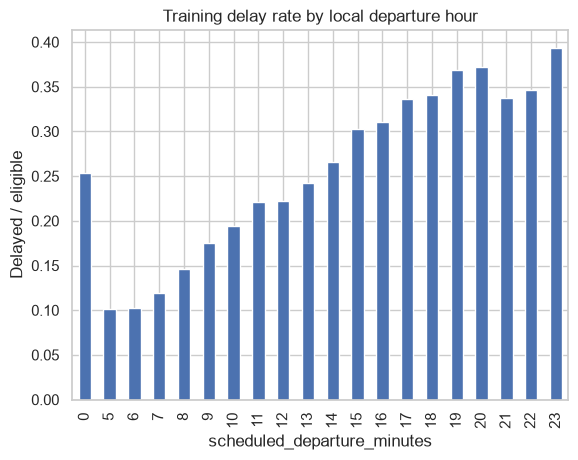

In [13]:
hours = train['scheduled_departure_minutes']//60
train.groupby(hours)['delayed_departure'].mean().plot.bar(title='Training delay rate by local departure hour')
plt.ylabel('Delayed / eligible')
plt.show()

Cleaning matches the existing handoff, including missingness. Cancelled/unknown-label
rows stay as context, and no statistical outlier deletion was applied.
Continue to [02 — Feature Engineering](02_feature_engineering.ipynb).